# EDA 2: the price against its day-ahead inputs

Core zones first: DE_LU, FR and ES, read from the config by `group: core`. The Swedish zones SE_1 to SE_4 come last, in one section, as extra zones that are not part of the approved Milestone 1 scope.

**Train data only.** Every figure and number uses delivery days before `splits.validation_start` (2026-06-23). No validation or test day is read.

How to read this notebook:

- Each code cell calls a function of `epf.eda.driver_figures`. The command `python -m epf.eda.driver_figures` calls the same functions and writes the figures to `reports/figures/`.
- Each cell prints the tables behind its figure. Every number in a finding below is copied from those tables.
- Prices are in EUR/MWh and forecasts in MW. Hours, delivery days, months and years are in market time (Europe/Berlin).
- The price is compared with the day-ahead forecasts only: load, wind and solar. `actual_load` is not used anywhere, because the actual load of a delivery day is not known when its price is set (PROJECT_CONTEXT §5).
- Nothing is filled. An hour with an empty input is left out of that comparison, and the tables say how many hours were left out.
- A sentence that starts with "Guess:" is my reading of a cause. The data in this notebook does not test it.

EDA 1 left three guesses open. Sections 2 and 3 test them:

1. The midday price dip follows solar output.
2. Negative prices follow solar output.
3. Spikes fall on hours of high load with little wind and solar.

In [1]:
from epf.config import load_config
from epf.data.validate import HOURLY, QUARTER_HOUR
from epf.eda import driver_figures as figures
from epf.eda.price_figures import print_tables

config = load_config()
hourly = figures.load_tables(config, HOURLY, figures.CORE)
print_tables({"Train data, hourly table, core zones": figures.train_period(hourly, config)})


Train data, hourly table, core zones
       time_steps             first              last  empty_prices
DE_LU       65519  2019-01-01 00:00  2026-06-22 23:00             0
FR          65519  2019-01-01 00:00  2026-06-22 23:00             0
ES          65519  2019-01-01 00:00  2026-06-22 23:00             0


The hourly train set has 65519 hours per zone, from 2019-01-01 00:00 to 2026-06-22 23:00, and no empty price.

## 1. Price against the load, wind and solar forecast

Residual load (DECISIONS entry 42) is the load forecast minus the wind forecast minus the solar forecast. Wind is onshore plus offshore where the zone has an offshore column. It is the part of the load that other plants must cover. The rank correlation is the Pearson correlation of the ranks, so it measures whether the price rises when the input rises, whatever the shape of the curve.

Each panel counts every train hour in cells. The colour scale is logarithmic. The black line is the median price in 20 bins of the input that hold the same number of hours.


Rank correlation of the price with each input
       load_forecast  wind_forecast  solar_forecast  residual_load
DE_LU           0.21          -0.27           -0.11           0.52
FR              0.27          -0.14           -0.10           0.39
ES              0.20          -0.19           -0.15           0.41

Hours left out because the input or the price is empty
       load_forecast  wind_forecast  solar_forecast  residual_load
DE_LU             50              3               3             51
FR                 0            350             376            480
ES                 1            385             169            505

Rank correlation of the price with each input per year, DE_LU
      load_forecast  wind_forecast  solar_forecast  residual_load
year                                                             
2019           0.58          -0.37            0.08           0.86
2020           0.46          -0.37           -0.04           0.82
2021           0.27          -0.32

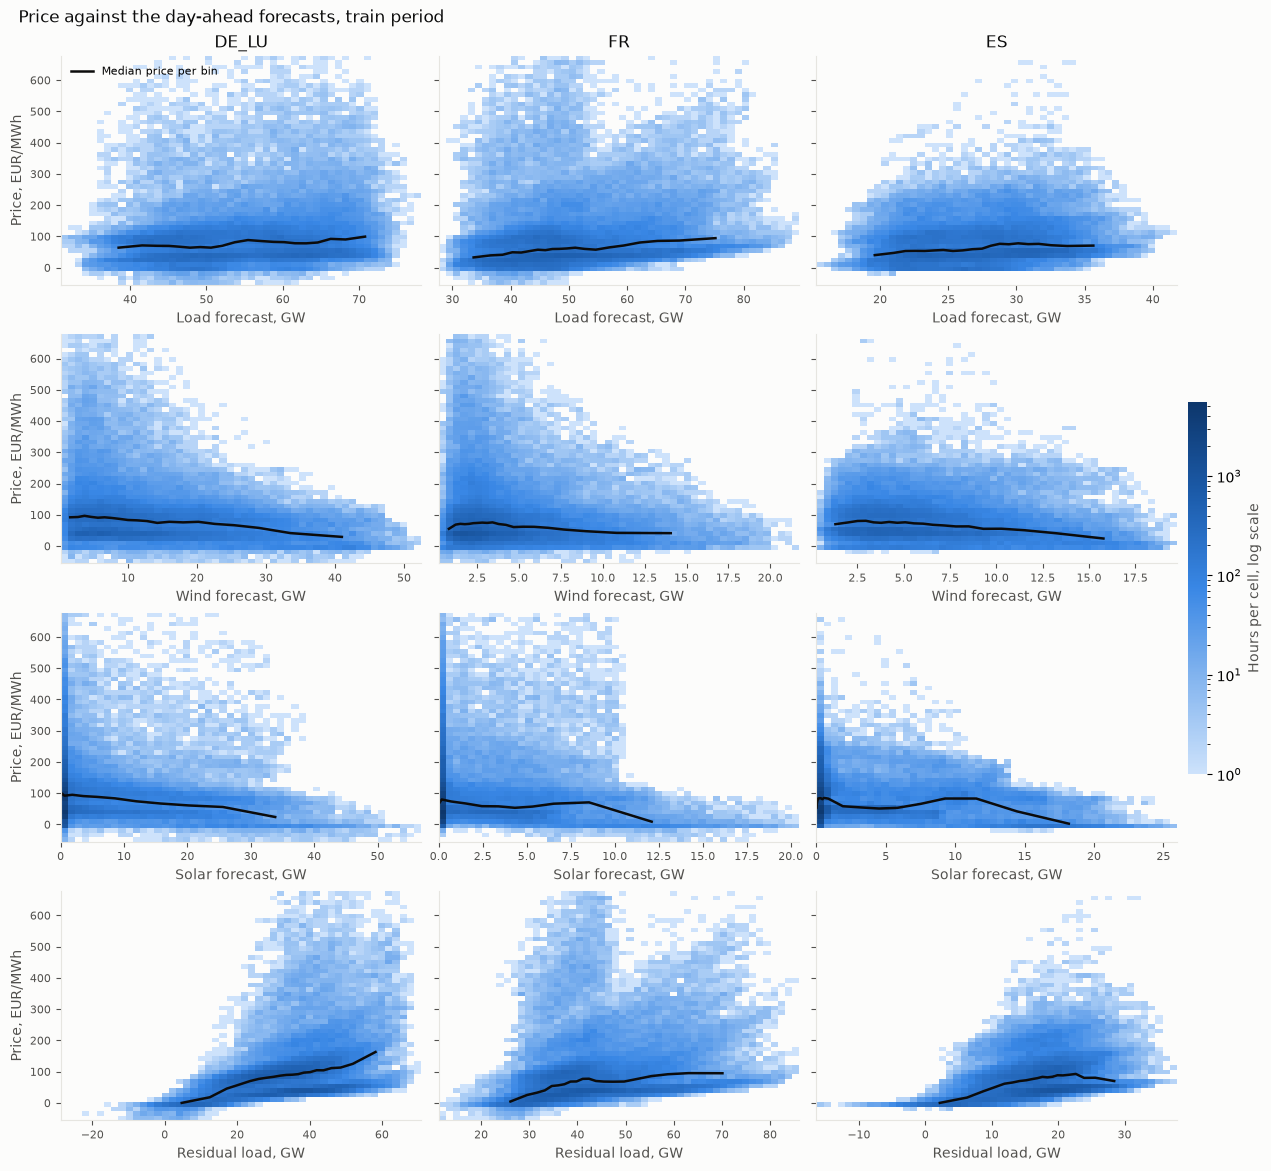

In [2]:
tables, figure = figures.price_vs_drivers(hourly, config)
print_tables(tables)

**Finding.** The price follows the residual load far more closely than any single forecast, and within one year the tie is close.

- Rank correlation with the price over the whole train period: residual load 0.52 in DE_LU, 0.39 in FR and 0.41 in ES. The load forecast alone gives 0.21, 0.27 and 0.20, the wind forecast -0.27, -0.14 and -0.19, the solar forecast -0.11, -0.10 and -0.15.
- Per year the tie to the residual load is much closer. DE_LU has 0.82 to 0.91 in every year except 2021 (0.57) and 2022 (0.68). FR has 0.60 to 0.81, except 0.24 in 2021 and in 2022. ES has 0.71 to 0.87, except 0.31 in 2021 and 0.51 in 2022.
- So the number for the whole period is low because the price level moved between years, not because the inputs say little. Section 5 looks at that.
- The median price rises with the residual load. DE_LU: -0.05 in the lowest bin (median residual load 4690 MW) and 162.91 in the highest (58229 MW). FR: 4.39 and 94.84. ES: 0.00 in the lowest bin, 92.63 in bin 17 and 69.94 in bin 20.
- The median price falls with the wind forecast: from 92.00 to 29.34 in DE_LU, from 70.00 to 24.10 in ES. FR is flatter, 55.14 in the lowest bin and 41.27 in the highest.
- The solar forecast gains weight over the years. Its rank correlation with the price goes from 0.08 in 2019 to -0.37 in 2026 in DE_LU, from 0.03 to -0.42 in FR and from 0.11 to -0.46 in ES.
- Hours left out because the residual load has an empty input: 51 in DE_LU, 480 in FR and 505 in ES. The panels cover -55.64 to 678.27 and leave out 137 hours below and 75 above in DE_LU, 60 and 121 in FR, 0 and 1 in ES.
- The solar forecast has fewer than 20 bins in DE_LU and FR, because the many hours with a forecast of zero fall into one bin, of 29482 and 32572 hours. In ES the lowest bin has a median of 4.21 MW, so the ES solar forecast is not zero at night. Guess: solar thermal plants with storage.
- For RQ2 this says the forecasts carry information the price history alone does not. The residual load is a candidate feature for LightGBM.
- Guess: in ES the highest residual loads fall mostly in the cheap years 2019 and 2020, which had less wind and solar, and that pulls the median of the top bins down.

## 2. Guess 1: the midday dip follows solar output

The delivery days of each zone are sorted into three groups of equal size by the sum of the solar forecast over the day. The figure shows the price minus the mean price of its own day, as a median per hour. Taking the daily mean away removes the price level, so years with different levels can be compared.


Delivery days per group of the daily solar forecast (group 1 = least solar)
       days_group_1  days_group_2  days_group_3  days_left_out  median_gwh_group_1  median_gwh_group_2  median_gwh_group_3
DE_LU           909           909           909              3               39.54              144.47              264.63
FR              903           902           903             22               22.57               46.84               88.46
ES              907           907           908              8               40.93               83.90              160.09

Median of the price minus the mean price of its day, group 1
      DE_LU     FR     ES
hour                     
0    -12.78  -8.48  -0.96
1    -15.45 -11.95  -5.34
2    -17.44 -14.25  -8.24
3    -19.38 -18.09  -9.67
4    -18.89 -19.52 -10.10
5    -14.76 -15.45  -8.58
6     -6.13  -6.29  -4.27
7      7.23   6.69   1.18
8     12.30  10.69   4.02
9     10.85  10.77   4.55
10     7.33   7.28   3.13
11     5.27   5.28   1.58
12   

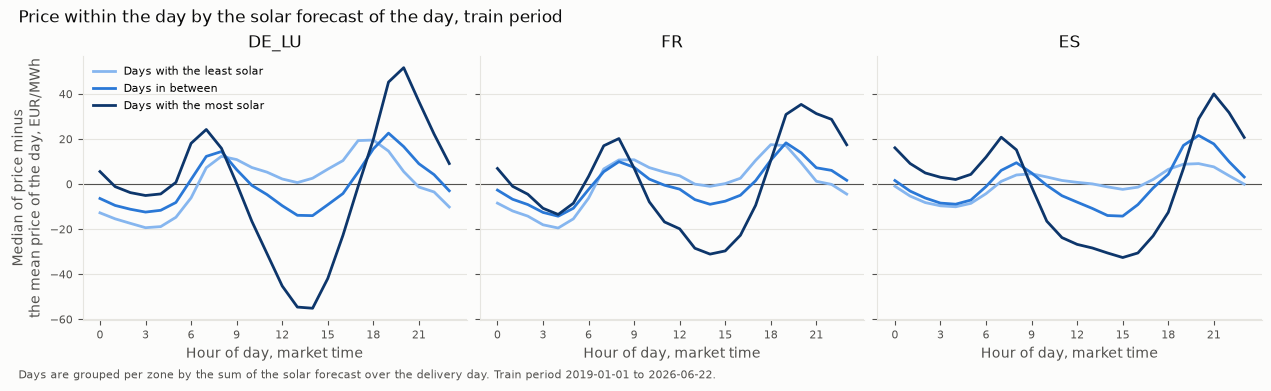

In [3]:
tables, figure = figures.solar_midday(hourly, config)
print_tables(tables)

**Finding.** Guess 1 holds as an association: the midday dip exists only on days with a solar forecast, and it deepens with it.

- DE_LU at hour 14: the price is 2.57 above the mean of the day on the days with the least solar, 14.03 below it on the days in between and 55.13 below it on the days with the most solar.
- FR at hour 14: -1.02, -8.99 and -31.10. ES at hour 15: -2.37, -14.24 and -32.62.
- On the days with the least solar there is no midday dip in DE_LU. The lowest hour is at night, -19.38 at hour 3, and hours 10 to 16 lie above the mean of the day.
- The evening peak grows with the solar forecast too. DE_LU at hour 20: 5.52 above the mean of the day with the least solar and 51.63 with the most. ES at hour 21: 7.62 and 39.99.
- Each group has 909 days in DE_LU, 902 or 903 in FR and 907 or 908 in ES. A day with an empty solar hour is left out: 3 days in DE_LU, 22 in FR and 8 in ES. The median day has 39.54, 144.47 and 264.63 GWh of solar forecast in the three DE_LU groups.
- Limit: days with much solar are summer days. They are longer and have a lower load. The figure cannot separate solar from season, so this is support for guess 1, not proof.

## 3. Guesses 2 and 3: negative prices and spikes against the residual load

The train hours of each zone are sorted into ten bins of equal size by residual load. Bin 1 holds the tenth of the hours with the lowest residual load. The spike rule is the one of EDA 1 (DECISIONS entry 38). The last three tables give the load forecast, and wind, solar and residual load as a percentage of the load forecast, as medians over the negative hours, the spike hours and all hours.


Hours per bin of the residual load
     DE_LU    FR    ES
bin                   
1     6547  6504  6502
2     6547  6504  6501
3     6547  6504  6501
4     6546  6504  6505
5     6547  6504  6499
6     6547  6503  6500
7     6546  6504  6502
8     6547  6504  6501
9     6547  6504  6501
10    6547  6504  6502

Hours with a negative price per bin of the residual load (bin 1 = lowest)
     DE_LU    FR    ES
bin                   
1     2275  1187  1240
2       67   260    89
3        4    83     0
4        0    41     0
5        0    19     0
6        0    15     0
7        0     5     0
8        0     3     0
9        0     0     0
10       0     0     0

Share of the hours of the bin with a negative price, percent
     DE_LU    FR    ES
bin                   
1    34.75 18.25 19.07
2     1.02  4.00  1.37
3     0.06  1.28  0.00
4     0.00  0.63  0.00
5     0.00  0.29  0.00
6     0.00  0.23  0.00
7     0.00  0.08  0.00
8     0.00  0.05  0.00
9     0.00  0.00  0.00
10    0.00  0.00  0.00

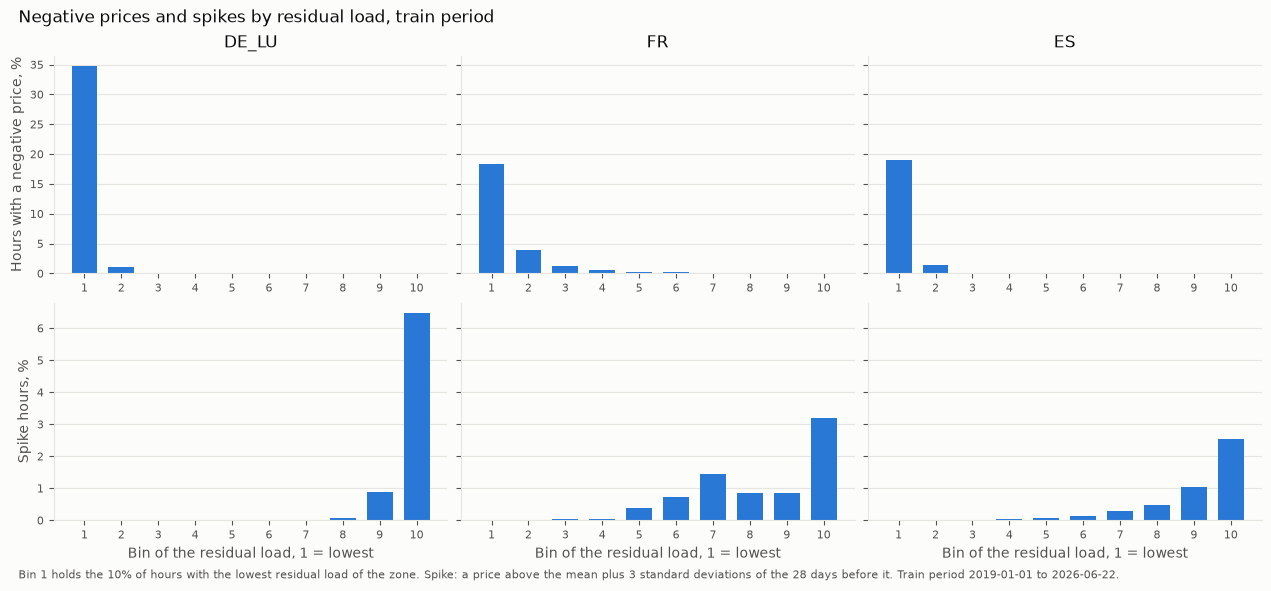

In [4]:
tables, figure = figures.negative_spike_by_residual(hourly, config)
print_tables(tables)

**Finding.** Negative prices sit at the lowest residual load and spikes at the highest. Guess 2 holds in part, guess 3 holds in DE_LU and ES and is weak in FR.

Negative prices (guess 2):

- DE_LU: 2275 of the 2346 negative hours are in bin 1, 67 in bin 2 and 4 in bin 3. In bin 1 the price is negative in 34.75% of the hours.
- ES: 1240 in bin 1 and 89 in bin 2. FR is wider: 1187 in bin 1, 260 in bin 2, and some up to bin 8.
- In the negative hours the solar forecast is large: a median of 47.97% of the load forecast in DE_LU, 23.68% in FR and 69.09% in ES. Over all hours it is 0.47%, 0.06% and 2.38%.
- But in DE_LU wind is as large as solar in those hours: 47.04% of the load forecast, against 22.49% over all hours. So negative prices in DE_LU follow wind and solar together. In ES it is solar: wind is 22.82% in the negative hours and 21.62% over all hours.
- FR is different. In its negative hours the residual load is still 66.12% of the load forecast. Guess: FR prices go negative through coupling with its neighbours and through nuclear plants that do not ramp down. The data here does not test that.

Spikes (guess 3):

- DE_LU: 424 of the 486 spike hours are in bin 10, 58 in bin 9 and 4 in bin 8. In the spike hours the median load forecast is 65282 MW, against 54576 MW over all hours. Wind is 6.75% of the load forecast, against 22.49%, and solar 0.59%.
- ES: 166 of 298 spike hours are in bin 10. The load forecast is 30730 MW against 27135 MW, and wind 13.29% against 21.62%.
- FR is weak: 208 of 490 spike hours are in bin 10 and 95 in bin 7. Guess: many FR spikes of 2022 came from nuclear outages, which the residual load does not see.
- Even in bin 10 a spike is rare: 6.48% of the hours in DE_LU, 3.20% in FR and 2.55% in ES. A high residual load is needed for a spike in DE_LU, but it does not make one.

Hours left out because the residual load is empty: 51 in DE_LU, 480 in FR and 505 in ES. They hold 0, 3 and 99 negative hours and 0, 3 and 7 spike hours. So 99 of the ES negative hours are not in the figure.

## 4. Hourly against 15-minute prices

From delivery day 2025-10-01 the market clears a price for every quarter-hour. Experiment H uses the mean of the four prices of an hour (DECISIONS entry 21). This section looks at what that mean hides. The spread of an hour is its highest minus its lowest quarter-hour price.


Train data, quarter_hour table, core zones
       time_steps             first              last  empty_prices
DE_LU       25440  2025-10-01 00:00  2026-06-22 23:45             0
FR          25440  2025-10-01 00:00  2026-06-22 23:45             0
ES          25440  2025-10-01 00:00  2026-06-22 23:45             0

Spread inside the hour: highest minus lowest quarter-hour price
       hours  hours_left_out  median   q75   q95    max  zero_percent
DE_LU   6360               0   13.98 28.04 71.64 333.30          0.22
FR      6360               0   14.63 27.54 60.79 332.63          2.00
ES      6360               0    6.00 15.19 41.85 121.73          6.60

Median spread per hour of day
      DE_LU    FR    ES
hour                   
0     12.80 20.40  9.96
1      6.46 10.77  5.43
2      3.71 12.09  3.68
3      2.68  7.31  1.50
4      4.54  5.99  1.04
5     11.32 10.60  3.57
6     17.97 15.60  7.81
7     20.94 17.50 10.54
8     27.82 24.92 15.89
9     28.81 28.60 22.63
10    21.81 19.37 10

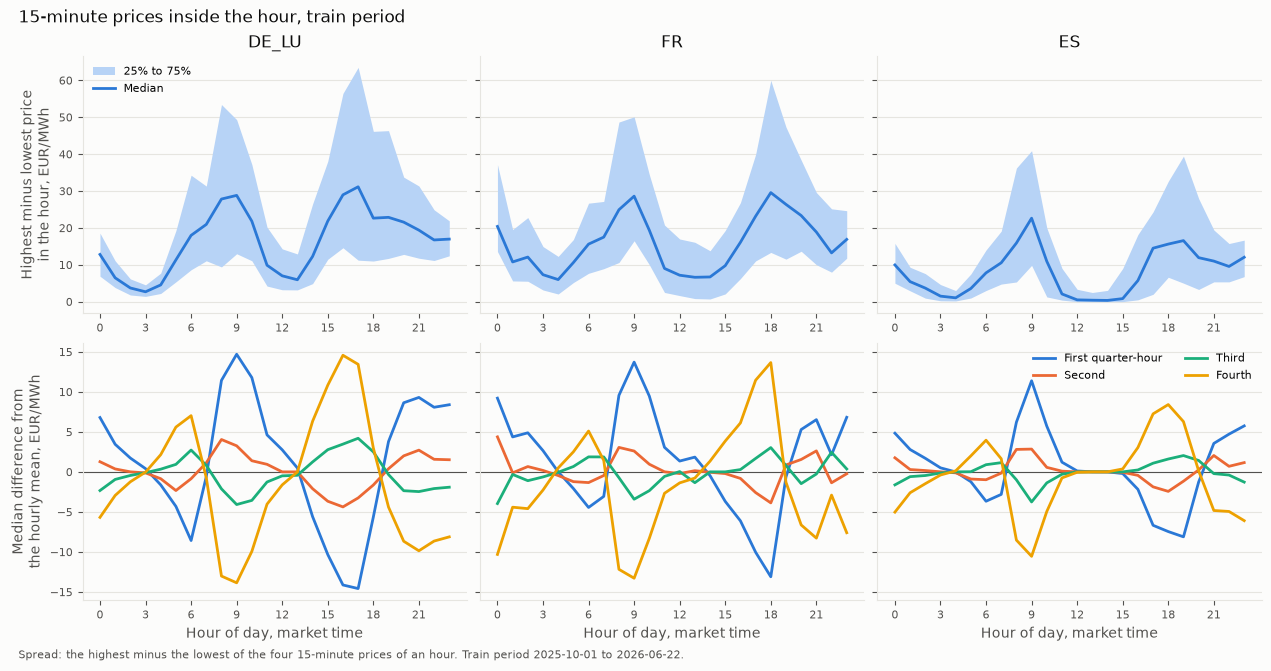

In [5]:
quarter_hourly = figures.load_tables(config, QUARTER_HOUR, figures.CORE)
print_tables({"Train data, quarter_hour table, core zones":
              figures.train_period(quarter_hourly, config)})
tables, figure = figures.quarter_hour_spread(quarter_hourly, config)
print_tables(tables)

**Finding.** The four prices of an hour differ by a median of about 14 EUR/MWh in DE_LU and FR, and they differ in a regular pattern.

- The 15-minute train set has 25440 quarter-hours per zone, from 2025-10-01 00:00 to 2026-06-22 23:45. That is 6360 hours, and every one has four prices.
- Median spread: 13.98 in DE_LU, 14.63 in FR and 6.00 in ES. The 95% quantile is 71.64, 60.79 and 41.85, the largest spread 333.30, 332.63 and 121.73.
- The four prices are equal in 0.22% of the hours in DE_LU, 2.00% in FR and 6.60% in ES.
- The spread follows the day. In DE_LU the median is 28.81 at hour 9 and 31.14 at hour 17, and 2.68 at hour 3. In ES it is 0.34 at hour 14 and 22.63 at hour 9.
- Inside the hour the price runs in one direction. In DE_LU at hour 9 the first quarter-hour is a median of 14.69 above the mean of the hour and the fourth 13.86 below it. At hour 17 it is the other way round: 14.58 below and 13.44 above.
- FR and ES show the same pattern: 13.71 above and 13.29 below at hour 9 in FR, 11.38 and 10.55 in ES. At hour 18 FR has 13.11 below and 13.66 above.
- Guess: demand and solar output change steadily through the hour, while much of the supply is scheduled in hourly blocks. In the morning the price falls through the hour as solar comes in, and in the evening it rises as solar leaves.
- Every hour of day has 265 hours, hour 2 included: the train period has one 25-hour day, 2025-10-26, and one 23-hour day, 2026-03-29.
- For the models: experiment Q is not experiment H at a finer grid. The position of the quarter-hour in its hour carries a signal of its own, and the D-7 naive forecast already contains it.

## 5. The high-price period of 2021 and 2022

Rule (DECISIONS entry 45): for every month the mean price is taken per zone and then averaged over the three core zones. A month is high when that value is above 2 times its median over all train months. The period runs from the first to the last such month and is the same for the three zones. The factor is `eda.regime_factor` in the config. It is a convention and was not tuned.


High-price period, one for all zones
           median_of_monthly_means  threshold first_month last_month  months_above  months_in_period
all zones                    68.62     137.24     2021-09    2022-12            16                16

The three months outside the period with the highest mean price over the zones
         mean_price
month              
2023-02      136.85
2025-02      119.83
2023-01      106.49

Price per period, DE_LU
                   hours   mean  median   q05    q95  negative_hours  rank_correlation_with_residual_load
period                                                                                                   
Before             23375  41.00   38.90  5.31  84.47             636                                 0.70
High-price period  11689 218.17  193.16 48.01 484.87              81                                 0.66
After              30455  88.87   92.05 -0.01 161.09            1629                                 0.86

Price per period, FR
   

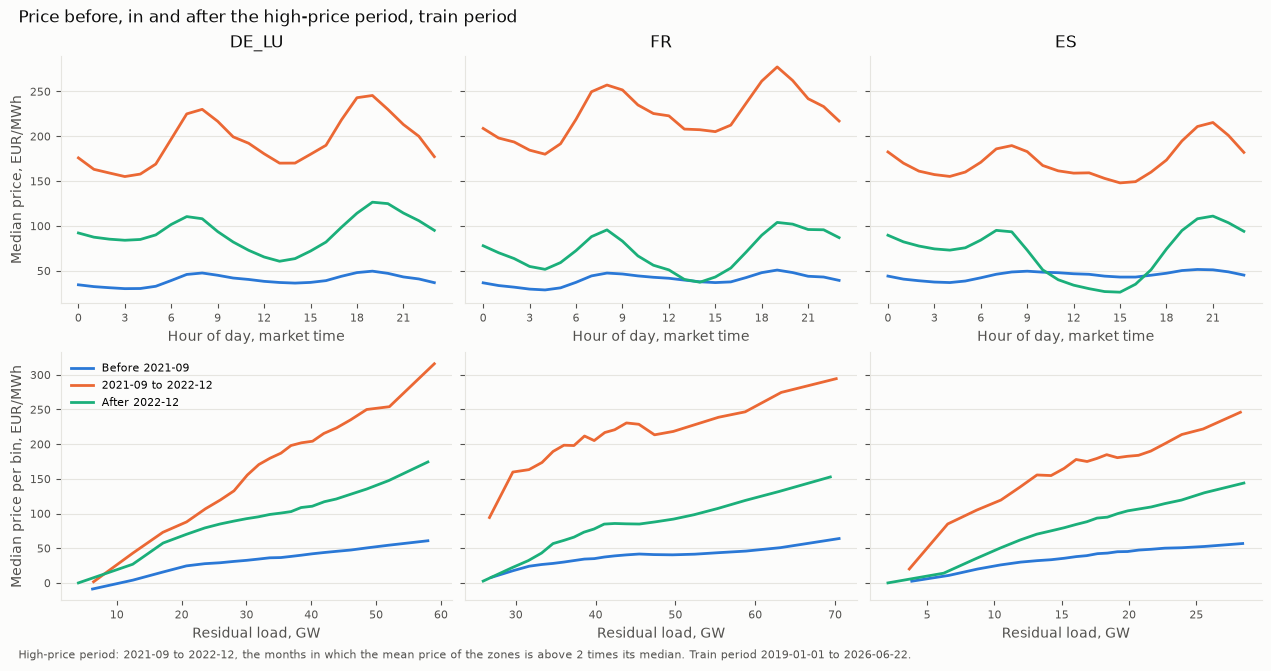

In [6]:
tables, figure = figures.regime(hourly, config)
print_tables(tables)

**Finding.** The train set holds three price regimes, not two. The period after 2022 did not return to the period before it.

- The rule gives 2021-09 to 2022-12: 16 months above the threshold of 137.24, which is 2 times the median of 68.62, with no month below it in between.
- The end of the period is a close call. February 2023 has a mean of 136.85, just under the threshold. The next highest month outside the period is February 2025 with 119.83.
- Level, as the median price before, in and after the period: 38.90, 193.16 and 92.05 in DE_LU. 39.91, 223.95 and 73.46 in FR. 45.17, 172.21 and 75.00 in ES.
- Spread: the 95% quantile in DE_LU is 84.47 before, 484.87 in the period and 161.09 after.
- Low prices moved the other way. After the period the 5% quantile is -0.01 in DE_LU and 0.00 in FR and ES. DE_LU has 636 negative hours before, 81 in the period and 1629 after. ES has all of its 1428 negative hours after the period.
- The daily shape changed. Before the period it is nearly flat: in DE_LU the median runs from 30.04 at hour 3 to 49.55 at hour 19. After it there is a deep midday dip: 63.53 at hour 14 against 126.47 at hour 19 in DE_LU, and 26.10 at hour 15 against 110.96 at hour 21 in ES.
- The same residual load buys a different price in each period. In the highest of the 20 bins the DE_LU median price is 60.75 before, 315.88 in the period and 174.34 after. In the lowest bin it is -8.80, 1.64 and -0.01.
- Within a period the price follows the residual load well: the rank correlation in DE_LU is 0.70 before, 0.66 in the period and 0.86 after. In FR it is 0.46, 0.29 and 0.68, in ES 0.52, 0.51 and 0.78.
- Guess: the gas price set the level and the slope in the period. Fuel prices are not in the project scope, so this is not tested.
- For the models: one model fitted on all years averages three different responses to the same inputs. How much history to train on is a choice to make on the validation set. A lagged price carries the level, which is a reason to expect LightGBM to cope better than a model without it.

## 6. Holidays against working days

A holiday is a nationwide public holiday of the country of the zone, from the `holidays` package (DECISIONS entry 46). The days are compared in four types: working day, holiday on Monday to Friday, Saturday and Sunday. A holiday on a Saturday or Sunday counts as that weekend day.

Holidays are not spread evenly over the year, so the plain medians mix the holiday with the season. The third table corrects for that: it takes the daily mean price of each holiday minus the median daily mean of the working days within 7 days before and after it.

Regional holidays count as working days. The last four tables measure what that leaves out.


Delivery days per day type
       Working day  Holiday, Mon to Fri  Saturday  Sunday  holidays_on_a_weekend
DE_LU         1891                   59       390     390                     10
FR            1882                   68       390     390                     15
ES            1895                   55       390     390                      9

Median of the daily mean price per day type
       Working day  Holiday, Mon to Fri  Saturday  Sunday
DE_LU        85.52                36.50     62.08   53.95
FR           68.51                35.16     50.14   41.13
ES           68.62                57.87     52.80   47.94

Holiday on Monday to Friday: daily mean price minus the median of the working days within 7 days
       days  days_left_out  median    q25   q75  below_zero_percent
DE_LU    59              0  -20.24 -49.09 -7.19               89.83
FR       68              0  -16.91 -33.06 -8.25               95.59
ES       55              0  -11.18 -28.78 -1.46               76.36



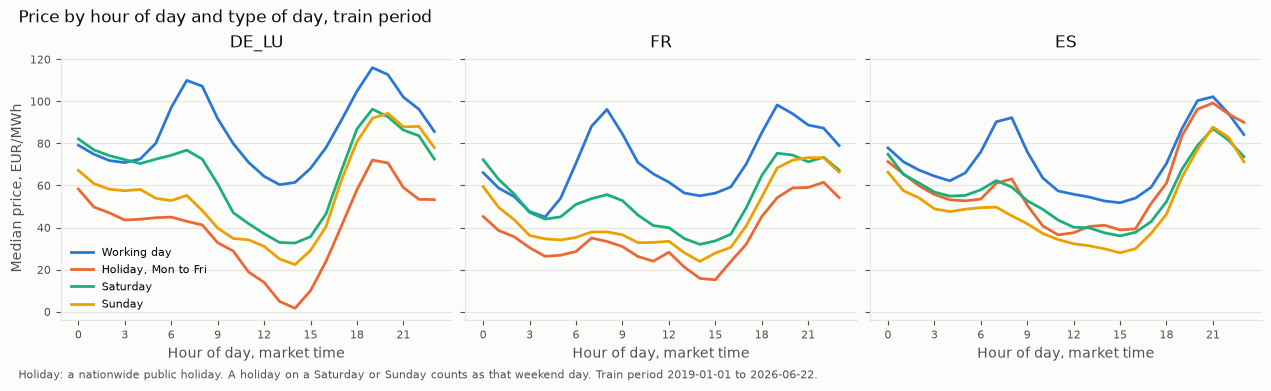

In [7]:
tables, figure = figures.holidays(hourly, config)
print_tables(tables)

**Finding.** A holiday on a weekday is priced like a Sunday or lower, and it loses the morning peak.

- Days in the train set: DE_LU has 59 holidays on Monday to Friday, 1891 working days and 390 Saturdays and Sundays each. FR has 68 and 1882, ES 55 and 1895. 10, 15 and 9 holidays fall on a weekend.
- Median of the daily mean price in DE_LU: 85.52 on working days, 62.08 on Saturdays, 53.95 on Sundays and 36.50 on holidays. FR: 68.51, 50.14, 41.13 and 35.16. In ES the holiday is closer to a working day: 68.62, 52.80, 47.94 and 57.87.
- Corrected for season, a holiday is still cheaper than the working days around it: a median of 20.24 lower in DE_LU, 16.91 in FR and 11.18 in ES. 89.83%, 95.59% and 76.36% of the holidays are below their neighbours.
- The shape changes too. In DE_LU the median price at hour 9 is 91.77 on a working day and 32.80 on a holiday. At hour 13 it is 60.38 and 4.90.
- For the models: a holiday flag is a justified calendar feature. The seasonal naive forecast takes the price of the same hour seven days earlier, so it will be too high on a holiday and too low a week after one.

Limit of the calendar, measured:

- Regional holidays on Monday to Friday that count as working days here: 53 in DE_LU, 94 in FR and 186 in ES. That is 2.80%, 4.99% and 9.82% of the working days.
- They hardly move the result. With these days taken out of the working days, the corrected holiday difference is -20.24 in DE_LU, -17.48 in FR and -11.61 in ES.
- The regional days themselves show no clear effect. In DE_LU the 35 days that are a holiday in up to 25% of the subdivisions are a median of 5.97 lower, the 13 days in 25% to 50% are 23.96 lower and the 5 days above 50% are 5.20 higher. In ES the three groups have -0.06 (161 days), -4.80 (14 days) and 0.39 (11 days). FR has 94 days at -0.85, all in the lowest group.
- These groups are small, and a share of subdivisions is not a share of people. The package lists 17 subdivisions for DE and FR and 20 for ES. They include the city of Augsburg, and for FR mostly overseas territories, which are outside the bidding zone.
- Luxembourg is part of DE_LU, and its holidays are not counted.

## 7. Extra zones: Sweden, north against south

**SE_1 to SE_4 are extra zones.** They were added on 19 Nov 2026 and are not part of the scope approved in Milestone 1 (DECISIONS entry 1). They get one section, no tuning and no features of their own. The core results above are complete without them.

The zones run from north (SE_1) to south (SE_4), which is their order in the config. Each zone is compared with the next one. Price levels differ several-fold between north and south, so the zones are compared on relative terms: the yearly mean divided by the mean of the four zones, and the price per hour divided by the mean price of the zone.

"Identical" means exactly the same price in the same hour (DECISIONS entry 48). The hours are split at delivery day 2024-10-30, when Nordic flow-based market coupling started. The Swedish zones have no solar forecast (DECISIONS entry 32), so their residual load is the load forecast minus the wind forecast.


Train data, hourly table, extra zones
      time_steps             first              last  empty_prices
SE_1       65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_2       65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_3       65519  2019-01-01 00:00  2026-06-22 23:00             0
SE_4       65519  2019-01-01 00:00  2026-06-22 23:00             0



Price over the train period
      hours  mean  median  negative_hours
SE_1  65519 34.84   25.99            1654
SE_2  65519 35.15   26.29            1949
SE_3  65519 56.73   38.10            1539
SE_4  65519 68.89   46.66            1509

Mean price per year
      SE_1  SE_2   SE_3   SE_4
year                          
2019 37.94 37.94  38.36  39.80
2020 14.39 14.39  21.19  25.86
2021 42.49 42.55  66.00  80.52
2022 59.06 61.95 129.21 152.10
2023 39.97 39.98  51.70  64.88
2024 25.05 24.64  35.77  49.71
2025 16.71 16.53  46.23  60.43
2026 52.47 52.32  75.38  88.01

Mean price per year divided by the mean of the zones
      SE_1  SE_2  SE_3  SE_4
year                        
2019  0.99  0.99  1.00  1.03
2020  0.76  0.76  1.12  1.36
2021  0.73  0.74  1.14  1.39
2022  0.59  0.62  1.28  1.51
2023  0.81  0.81  1.05  1.32
2024  0.74  0.73  1.06  1.47
2025  0.48  0.47  1.32  1.73
2026  0.78  0.78  1.12  1.31

Hours with exactly the same price in neighbouring zones, percent
      SE_1 = SE_2  S

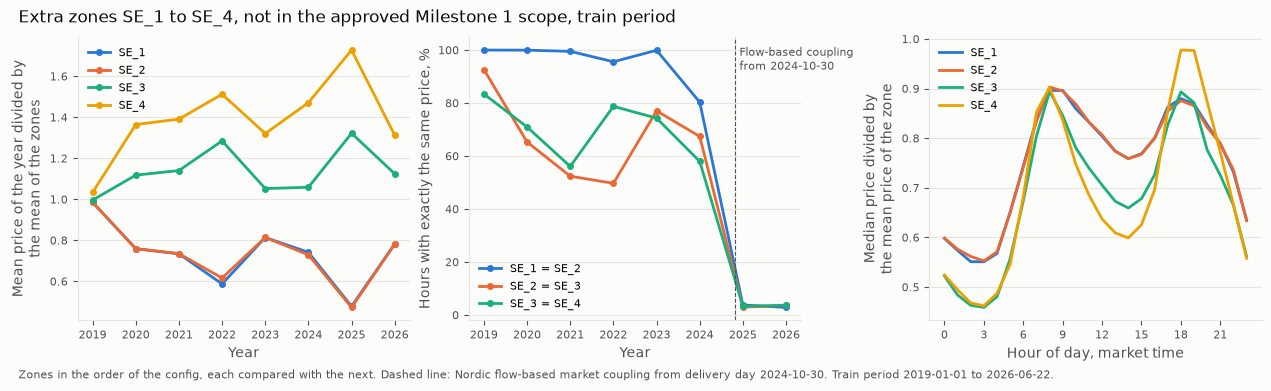

In [8]:
extra = figures.load_tables(config, HOURLY, figures.EXTRA)
print_tables({"Train data, hourly table, extra zones": figures.train_period(extra, config)})
tables, figure = figures.sweden(extra, config)
print_tables(tables)

**Finding (extra zones).** North and south have drifted apart in level, and SE_1 and SE_2 are near-duplicates of each other, though no longer hour for hour.

- Each zone has 65519 train hours and no empty price. The mean price over the train period is 34.84 in SE_1, 35.15 in SE_2, 56.73 in SE_3 and 68.89 in SE_4.
- In 2019 the four zones were level: 37.94, 37.94, 38.36 and 39.80, which is 0.99, 0.99, 1.00 and 1.03 of their mean. In 2025 SE_1 is at 16.71 and SE_4 at 60.43, which is 0.48 and 1.73 of the mean.
- So errors in EUR cannot be compared between these zones. The results will use relative MAE.
- SE_1 and SE_2 had exactly the same price in 98.61% of the hours before 2024-10-30 and in 3.41% of the hours from that day. By year: 99.98% in 2019, 80.32% in 2024, 3.76% in 2025 and 2.84% in 2026.
- They are still close. From 2024-10-30 the median absolute difference between SE_1 and SE_2 is 1.23 and its 95% quantile 12.74. Their yearly means are 16.71 and 16.53 in 2025 and 52.47 and 52.32 in 2026.
- The other pairs lost their identical hours at the same date: SE_2 and SE_3 went from 69.34% to 2.97%, SE_3 and SE_4 from 72.22% to 3.30%. But they are far apart in level: the median absolute difference from 2024-10-30 is 20.53 between SE_2 and SE_3 and 5.85 between SE_3 and SE_4.
- Guess: flow-based coupling prices the limits of the grid hour by hour, so zones that used to clear at one price now differ by small amounts. The data here does not test that.
- The price follows the residual load in all four zones: the rank correlation is 0.49, 0.56, 0.54 and 0.47. The wind forecast alone gives -0.37, -0.47, -0.30 and -0.32. 216 hours are left out in each zone because the load or the wind forecast is empty.
- The daily shape is flatter in the north. In SE_1 the median price runs from 0.55 of the zone's mean at hour 3 to 0.90 at hour 8. In SE_4 it runs from 0.46 at hour 3 to 0.98 at hour 18, with a midday dip to 0.60 at hour 14, against 0.76 in SE_1. The medians stay below 1 because the mean lies above the median in every zone.
- Negative prices occur in all four zones: 1654, 1949, 1539 and 1509 hours.
- Limit: SE_4 has the deepest midday dip and no usable solar forecast, so a model for SE_4 cannot see what drives that dip.
- For the plan: SE_1 and SE_2 will give near-duplicate results. That is why they are the first Swedish zones to be cut if a core item is at risk (PROJECT_CONTEXT §1).

## What became of the three guesses of EDA 1

1. The midday dip follows solar output: supported. On the third of the days with the most solar forecast the DE_LU price at hour 14 is 55.13 below the mean of the day, and on the third with the least it is 2.57 above it. Season is not separated out.
2. Negative prices follow solar output: partly. They follow a low residual load: 2275 of the 2346 negative hours of DE_LU are in the lowest tenth. In ES that is solar. In DE_LU wind is as large as solar in those hours. In FR the residual load is still 66.12% of the load forecast when the price is negative.
3. Spikes fall on hours of high load with little wind and solar: supported in DE_LU, where 424 of 486 spike hours are in the highest tenth of the residual load, and in ES with 166 of 298. Weak in FR with 208 of 490.

## Not in this notebook

Weather forecasts, fuel prices and cross-border flows are not compared with the price here. The first is a later sub-experiment and the other two are outside the project scope.